# Fusion Equilibrium Challenge — Conv Decoder V2 Training (FULL split, GPU)

Trains `PsiConvDecoderV2` (`fec_common/conv_decoder.py`) on the **entire** train/val split
(4929 train shots / 704 val shots) -- same split as `train_conv_decoder_full.ipynb`'s V1 run,
so results are directly comparable.

**Why V2**: the real composite scorer (`04_local_score.py`, not just pointwise R2) showed V1
hitting `psi_R2≈0.99` but the Consistency term's shape scalars -- kappa, tri_top/bot,
R_axis/Z_axis -- sitting at only 0.68-0.78. Those come from the scorer re-tracing the
**predicted** ψ's LCFS contour, so no auxiliary scalar head can shortcut it; the fix has to be
ψ's own spatial fidelity. V2 adds:
- **CoordConv** -- concatenates fixed (R,Z) coordinate channels into every decoder block, so
  the network has absolute-position awareness (helps R_axis/Z_axis specifically, which are
  defined by absolute grid position).
- **Bilinear-upsample decoder blocks instead of ConvTranspose2d** -- avoids the checkerboard
  artifacts transposed convs are known for, which corrupt the contour the scorer traces.
- **Residual blocks** at each resolution stage for more capacity without harder optimization.
- **Boundary-weighted loss** -- upweights pixel error near the separatrix (steep-gradient
  region), exactly where kappa/tri_top/tri_bot/volume are measured, instead of spending most
  gradient budget on the easy flat interior/exterior.

**Run this as a separate Colab instance** from `train_conv_decoder_full.ipynb` if that's still
running -- different checkpoint file (`flux_conv_decoder_v2.pt`), no collision.

Needs a GPU with real headroom: ψ targets are stored float16 on-GPU (~9GB at this scale) -- a
16GB+ card (T4/L4/A100) is required.

Needs the Drive-synced `code/run/` and `code/artifacts/features/` (from local `00`/`01`) to
already exist -- this does NOT re-extract features, only trains a new model against the 01
cache's scaler/split/meta.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# torch ships with Colab already -- nothing to pip install for this notebook.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import sys
from pathlib import Path

FOLDER_NAME = "EXPERIMENTS/FEC_NeurIPS/code"
CODE_DIR = Path("/content/drive/MyDrive") / FOLDER_NAME
RUN_DIR = CODE_DIR / "run"
ARTIFACTS_DIR = CODE_DIR / "artifacts"

assert RUN_DIR.exists(), f"{RUN_DIR} not found -- check Drive sync and FOLDER_NAME above"
sys.path.insert(0, str(RUN_DIR))

from fec_common.config import ensure_starter, log  # noqa: E402

ensure_starter()
import torch
assert torch.cuda.is_available(), "No GPU attached -- Runtime > Change runtime type > GPU"
print("CUDA:", torch.cuda.get_device_name(0),
     f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


CUDA: NVIDIA L4 23.7 GB


## 0b. Sanity-check the 01 cache synced correctly

Insync can lag on large binary files (`frame_index.npz` is tens of MB) even after a small `.py`
edit has already synced. Catch that here, with a clear message, instead of a confusing
traceback three calls deep.

In [ ]:
import json
import numpy as np

_idx = np.load(ARTIFACTS_DIR / "features" / "frame_index.npz", allow_pickle=True)
_split = json.load(open(ARTIFACTS_DIR / "features" / "split.json"))
_n_files = len(_idx["file_names"])
_max_split_id = max(max(_split["train"]), max(_split["val"]), max(_split["test"]))
print(f"file_names entries: {_n_files}  (train {len(_split['train'])} / val {len(_split['val'])})")

assert _n_files > _max_split_id, (
    f"frame_index.npz only has {_n_files} file_names entries but split.json references shot id "
    f"{_max_split_id} -- Drive sync is likely still catching up. Wait, then re-run this cell."
)
print("frame_index.npz looks fully synced.")
del _idx, _split, _n_files, _max_split_id


file_names entries: 7041  (train 4929 / val 704)
frame_index.npz looks fully synced.


## 0c. Sanity-check the V2 code synced correctly

The `arch="v2"` support in `train_conv_decoder_colab.py` and the `PsiConvDecoderV2` class in
`conv_decoder.py` were added after the files above may have already synced once -- confirm
they're actually here before a multi-hour run, instead of finding out via an ImportError or
(worse) silently training V1 anyway if the arch param were ever ignored.

In [ ]:
import fec_common.conv_decoder as _cd
import fec_common.train_conv_decoder_colab as _m

assert hasattr(_cd, "PsiConvDecoderV2"), (
    "PsiConvDecoderV2 not found in conv_decoder.py -- Drive sync hasn't caught up yet. Wait a "
    "bit and re-run this cell (or Runtime > Restart runtime if it still fails after waiting)."
)
assert "v2" in _m._ARCHS, "train_conv_decoder_colab.py's _ARCHS dict is missing 'v2' -- same sync issue."
print("V2 code is present and synced.")
del _cd, _m


V2 code is present and synced.


## 1. Train V2 on the full split

Loads ALL 4929 train shots + 704 val shots via the threaded parquet loader (16 workers -- drop
`load_workers` if Drive FUSE starts throttling/erroring on concurrent reads). Checkpoints the
best-val-loss model to `code/artifacts/models/flux_conv_decoder_v2.pt`.

In [5]:
from fec_common.train_conv_decoder_colab import train

model, history = train(
    n_shots_train=4929, n_shots_val=704, epochs=30, batch_size=256,
    load_workers=16, arch="v2", checkpoint_name="flux_conv_decoder_v2.pt",
)


[15:53:52] device: cuda (NVIDIA L4, 23.7 GB)
[15:53:54] loading 4929 train shots + 704 val shots from local parquet...


train shots:   0%|          | 0/4929 [00:00<?, ?shot/s]

val shots:   0%|          | 0/704 [00:00<?, ?shot/s]

[16:14:29]   1089024 train frames / 158282 val frames  (1235s)
[16:14:32] arch: v2 (PsiConvDecoderV2)
[16:21:41]   epoch  1/30  train_loss 0.03500  val_loss 0.01188  psi_R2 0.9894  q95_R2 0.9399  betaN_R2 0.9696  (415s)
[16:28:33]   epoch  2/30  train_loss 0.01515  val_loss 0.00888  psi_R2 0.9956  q95_R2 0.9543  betaN_R2 0.9754  (412s)
[16:35:24]   epoch  3/30  train_loss 0.01251  val_loss 0.00776  psi_R2 0.9880  q95_R2 0.9623  betaN_R2 0.9809  (411s)
[16:42:16]   epoch  4/30  train_loss 0.01112  val_loss 0.00722  psi_R2 0.9925  q95_R2 0.9643  betaN_R2 0.9791  (411s)
[16:49:07]   epoch  5/30  train_loss 0.01022  val_loss 0.00763  psi_R2 0.9918  q95_R2 0.9616  betaN_R2 0.9811  (411s)
[16:55:58]   epoch  6/30  train_loss 0.00922  val_loss 0.00789  psi_R2 0.9910  q95_R2 0.9596  betaN_R2 0.9842  (411s)
[17:02:49]   epoch  7/30  train_loss 0.00861  val_loss 0.00633  psi_R2 0.9870  q95_R2 0.9705  betaN_R2 0.9835  (411s)
[17:09:40]   epoch  8/30  train_loss 0.00818  val_loss 0.00638  psi_R2 0

## 2. Plot loss and accuracy

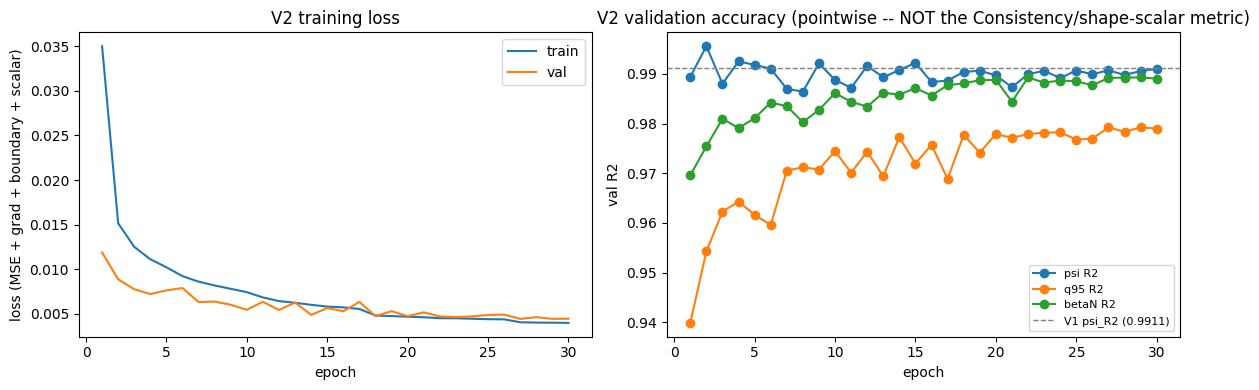

V2 best epoch: psi_R2=0.9956


In [6]:
import matplotlib.pyplot as plt

epochs_ = [h["epoch"] for h in history]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_, [h["train_loss"] for h in history], label="train")
ax1.plot(epochs_, [h["val_loss"] for h in history], label="val")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss (MSE + grad + boundary + scalar)"); ax1.legend()
ax1.set_title("V2 training loss")

ax2.plot(epochs_, [h["psi_r2"] for h in history], label="psi R2", marker="o")
ax2.plot(epochs_, [h["q95_r2"] for h in history], label="q95 R2", marker="o")
ax2.plot(epochs_, [h["betan_r2"] for h in history], label="betaN R2", marker="o")
ax2.axhline(0.9911, color="gray", linestyle="--", linewidth=1, label="V1 psi_R2 (0.9911)")
ax2.set_xlabel("epoch"); ax2.set_ylabel("val R2"); ax2.legend(fontsize=8)
ax2.set_title("V2 validation accuracy (pointwise -- NOT the Consistency/shape-scalar metric)")

plt.tight_layout(); plt.show()
print(f"V2 best epoch: psi_R2={max(h['psi_r2'] for h in history):.4f}")


---

## Next steps

The plot above is pointwise `psi_R2`/`q95_R2`/`betaN_R2` -- it does NOT show whether V2 actually
improved the Consistency term (kappa/tri_top/tri_bot/R_axis/Z_axis/volume/li), since those only
come from the real composite scorer, which runs **locally**, not in Colab:

```
uv run --python .venv code/run/04_local_score.py --model "Conv Decoder V2" --n-shots 50
```

`flux_conv_decoder_v2.pt` needs registering in `manifest.json` under a model name first
(wire this up once this checkpoint has synced back from Drive) -- then that command
gives the real, comparable `S` / `consistency` numbers against V1's existing
`S=0.9429` / `consistency=0.766` (n=50, in `code/artifacts/scores/local_score.json`).